# Hof_malanga_comparison — DiscEvolution vs Malanga et al. (2026)

**Goal.** Test whether the weak correlation between disc mass $M$ and stellar accretion rate $\dot M_*$ that Malanga et al. (2026) find for MHD-wind-driven discs (their Fig. 4) also appears in DiscEvolution's hybrid viscous + wind model. The population here is drawn from Malanga's inferred MHD-wind distributions (their Eq. 7 and Table 2, MHD-winds column) at $M_* = 1\,M_\odot$, with:
- fixed viscous $\alpha_{SS} = 10^{-4}$;
- $\psi = \alpha_{\rm tot}/\alpha_{SS} - 1$;
- $e_{\rm rad}$ mapped from Malanga's $f_M$ (their Eq. 6), via the steady-state wind relation and the code's $\lambda(e_{\rm rad},\psi)$ (Balogh et al. 2026, Eq. 16).

**Pipeline** (all in `example/StartHere/`):
- `sample_malanga_Hof.py` → `config/malanga/malanga_draws_Hof_N500_seed1.csv` (one row per disc: parameters + sampled age $t_{\rm age}$)
- `run_popsynth_malanga_Hof.sh` + `config/popsynth/DiscConfig_Hof_malanga.json` (grid 0.1–250 AU, 500 cells, 34 snapshots to 3 Myr)
- outputs: one `hof_malanga_w0_<id>_*.h5` per disc, next to a copy of the population CSV

**Units** (see `CLAUDE.md`):

| Quantity | Units |
|---|---|
| HDF5 `t` | yr |
| `time_snap` | Myr |
| `disk_Mass` | g (÷ `Msun`) |
| `disk_Mdot_star` | M$_\odot$/yr |
| `T` | K |
| `R` | AU |

**Notebook sections**
1. Run check (this first cell): completion, runtime, file size, and the gravitational-instability (GI) flag of the initial disc, i.e. Toomre $Q < 1.5$ (Toomre 1964; Balogh et al. 2026, Eq. 48), with the radius where the unstable region begins.
2. Parameter comparisons: achieved $f_M$ (instantaneous and cumulative) vs target, $M/\dot M$ vs analytic, disc spreading.
3. *(to come)* Fig. 4 reproduction: $\dot M$–$M$ at each disc's sampled age, with analytic $\omega = 0$ / $\omega = 0.4$ shadow populations and the Lupus subsample near $1\,M_\odot$.


In [1]:
# =====================================================================================
# 1. Run check: one row per disc in DATA_DIR (from check_malanga_pilot_Hof.py, reduced)
# =====================================================================================
# Columns:
#   id          disc id (row of the population CSV; run_name = hof_malanga_w0_<id>)
#   R0_au       characteristic radius R0 [AU]                       (population CSV)
#   M0_Msun     initial disc mass M0 [Msun]                         (population CSV)
#   complete    HDF5 attr complete = True AND last snapshot time_snap[-1] reached T_END_MYR (Myr)
#   runtime_h   wall-clock run_end - run_start [h] (HDF5 attrs; includes set-up)
#   size_MB     file size [MB]
#   GI_flag     gravitational instability of the INITIAL disc: Toomre (1964) Q = c_s Omega / (pi G Sigma)
#               (Balogh et al. 2026, Eq. 48) evaluated on every grid cell; flagged if Q < 1.5 anywhere
#               (see disc_setup_Hof.gi_check_toomre)
#   GI_R_au     radius [AU] where the disc ENTERS the unstable region going outward (innermost crossing
#               of Q = 1.5); NaN if not flagged. (The outer edge is in HDF5 attr GI_R_out_au.)
#   GI_source   'attr' = read from the HDF5 attrs written by run_model_Hof.py; 'recomputed' = file
#               written before those attrs existed (e.g. pilot1), recomputed here with the SAME function
#               from the t = 0 snapshot: gas surface density Sigma_G[0] and temperature T[0].
# Nothing is written to disk. Parameter comparisons come in later cells.
import os, sys, glob, re
from datetime import datetime
import numpy as np
import pandas as pd
import h5py

# ---- where things are -------------------------------------------------------------
DATA_DIR = "/home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/pilot1"
T_END_MYR = 3.0          # Myr, last snapshot of DiscConfig_Hof_malanga.json
T_END_RTOL = 1e-3        # relative tolerance for "reached the end" (dimensionless)

STARTHERE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))     # notebook lives in StartHere/notebooks/
if STARTHERE_DIR not in sys.path:
    sys.path.insert(0, STARTHERE_DIR)
from disc_setup_Hof import gi_check_toomre                            # Toomre Q GI check (Balogh+26 Eq. 48)
from DiscEvolution.constants import AU, Omega0, GasConst              # cm, s^-1, erg/mol/K

MU_EOS = 2.4             # mean molecular weight IrradiatedEOS uses (its default; make_eos does not pass mu)


def cs_omega_code_units(R_au, T_K, M_star):
    """Sound speed and Keplerian Omega in DiscEvolution code units (G = AU = Msun = 1), exactly as
    IrradiatedEOS / SimpleStar compute them:
        c_s = cs0 sqrt(T),  cs0 = (Omega0^-1 / AU) sqrt(GasConst / mu)     [AU per code-time unit]
        Omega_K = sqrt(M* / R^3)                                             [per code-time unit]
    R in AU, T in K, M* in Msun."""
    cs = (1 / Omega0 / AU) * np.sqrt(GasConst / MU_EOS) * np.sqrt(T_K)
    return cs, np.sqrt(M_star / R_au ** 3)


def run_row(path, draws):
    """Run-check row for one .h5 file (see column list above)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    row = {"id": disc_id, "R0_au": d.R0_au, "M0_Msun": d.M0_Msun}
    with h5py.File(path, "r") as h:
        a = h.attrs
        t_last = float(h["time_snap"][-1]) if ("time_snap" in h and len(h["time_snap"])) else np.nan   # Myr
        row["complete"] = bool(a.get("complete", False)) and bool(t_last >= T_END_MYR * (1 - T_END_RTOL))
        row["runtime_h"] = np.nan
        if "run_start" in a and "run_end" in a:
            row["runtime_h"] = (datetime.fromisoformat(str(a["run_end"]))
                                - datetime.fromisoformat(str(a["run_start"]))).total_seconds() / 3600
        row["size_MB"] = os.path.getsize(path) / 1e6
        if "GI_flag" in a and "GI_R_in_au" in a:                     # written by run_model_Hof.py
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = bool(a["GI_flag"]), float(a["GI_R_in_au"]), "attr"
        elif "Sigma_G" in h and len(h["Sigma_G"]) and np.isclose(h["time_snap"][0], 0.0):
            # recompute from the t = 0 snapshot (same criterion and function as the attrs)
            R = h["R"][:]                                                            # AU
            cs, Om = cs_omega_code_units(R, h["T"][0], d.Mstar_Msun)
            gi = gi_check_toomre(R, h["Sigma_G"][0], cs, Om)                         # Sigma_G[0] in g/cm^2
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = gi["GI_flag"], gi["GI_R_in_au"], "recomputed"
        else:
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = np.nan, np.nan, "unavailable"
    return row


def show_table(df, formats=None, default="{:.3g}"):
    """Return a display copy of `df` with float columns formatted as strings (default 3 significant
    figures; per-column overrides in `formats`) and NaN shown as '—'. Plain pandas: unlike
    DataFrame.style it does not need the optional jinja2 package (missing in the Nibi venv)."""
    formats = formats or {}
    out = df.copy()
    for col in out.columns:
        if pd.api.types.is_float_dtype(out[col]):
            fmt = formats.get(col, default)
            out[col] = out[col].map(lambda v: "—" if pd.isna(v) else fmt.format(v))
    return out

csvs = glob.glob(os.path.join(DATA_DIR, "malanga_draws_Hof_*.csv"))
assert len(csvs) == 1, f"expected exactly one malanga_draws_Hof_*.csv in {DATA_DIR}, found {csvs}"
draws = pd.read_csv(csvs[0]).set_index("id")
files = sorted(glob.glob(os.path.join(DATA_DIR, "hof_malanga_w0_*.h5")))
assert files, f"no hof_malanga_w0_*.h5 files in {DATA_DIR}"

run_check = pd.DataFrame([run_row(f, draws) for f in files]).sort_values("id").reset_index(drop=True)
print(f"{len(run_check)} discs in {DATA_DIR}  |  complete: {int(run_check.complete.sum())}  |  "
      f"GI-flagged (Q < 1.5): {int(run_check.GI_flag.fillna(False).sum())}  |  runtime median "
      f"{run_check.runtime_h.median():.2f} h, max {run_check.runtime_h.max():.2f} h  |  "
      f"total size {run_check.size_MB.sum():.0f} MB")
show_table(run_check, {"runtime_h": "{:.2f}", "size_MB": "{:.1f}"})


16 discs in /home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/pilot1  |  complete: 16  |  GI-flagged (Q < 1.5): 3  |  runtime median 0.14 h, max 1.20 h  |  total size 96 MB


,id,R0_au,M0_Msun,complete,runtime_h,size_MB,GI_flag,GI_R_au,GI_source
0,0,52,0.0766,True,0.10,3.9,False,—,recomputed
1,1,30.9,0.128,True,0.13,4.1,False,—,recomputed
2,2,25.1,0.0779,True,0.15,4.3,False,—,recomputed
3,3,13.3,0.0283,True,0.12,3.9,False,—,recomputed
4,4,11.2,0.0578,True,0.29,5.2,False,—,recomputed
5,5,11.4,0.0561,True,0.40,6.2,False,—,recomputed
6,6,1.23,0.00458,True,1.20,11.3,False,—,recomputed
7,7,22.6,0.0678,True,0.13,4.0,False,—,recomputed
8,8,281,0.0393,True,0.08,3.8,False,—,recomputed
9,9,1.71,0.0347,True,0.88,8.7,False,—,recomputed


## 2. Parameter comparisons: does each disc do what the mapping intended?
All quantities are evaluated at each disc's own sampled age $t_{\rm age}$ (population CSV, drawn from $N(1.6, 0.3)$ Myr; Malanga et al. 2026, Table 2).

**(a) Wind mass loss, $f_M$.** The $e_{\rm rad}$ mapping targets Malanga's $f_M$ through $\xi = \ln(1+f_M)/\ln(R_0/R_{\rm in})$ (Malanga et al. 2026, Eq. 6), with $R_{\rm in} = 0.03$ AU. Our grid starts at 0.1 AU, so no wind loss happens inside it. The steady-state value the runs can reach is therefore `f_M_grid_expected` $= (R_0/0.1\,{\rm AU})^\xi - 1$. Two measured versions:
- **instantaneous:** $f_{M,\rm inst}(t) = \dot M_{\rm wind}/\dot M_*$, with $\dot M_{\rm wind} = -\,dM/dt - \dot M_*$. It is measured over a $\pm$`DT_WIN_MYR` window around $t_{\rm age}$, which suppresses step-to-step noise. This is the quantity the steady-state mapping predicts.
- **cumulative:** $f_{M,\rm cum}(t) = M_{\rm wind}(t)/M_{\rm acc}(t)$, with $M_{\rm acc} = \int_0^t \dot M_*\,dt'$ and $M_{\rm wind} = M_0 - M(t) - M_{\rm acc}$. It includes the early, non-steady phase.

Caveats:
- $\dot M_*$ is measured at the inner cell, $R_c[0] \approx 0.11$ AU, from the gas velocity. Dust drifting through the inner edge faster than the gas ($d2g = 0.01$) is therefore counted as wind, at the $\lesssim 1\%$ level.
- For discs with $R_0 > 250$ AU, extending beyond the grid, mass leaving through the outer boundary is also counted as wind. These discs are shaded in panel (a).

**(b) Accretion timescale.** $\tau = M/\dot M_*$ at $t_{\rm age}$ is compared with the analytic $\omega = 0$ value $2\,t_{\rm acc,0}(1+f_M)$. That value follows from Malanga Eq. 5 with $\omega = 0$: $M = M_0\,e^{-t/2t_{\rm acc,0}}$ and $\dot M_* = M/[2\,t_{\rm acc,0}(1+f_M)]$ (form to verify against Tabone et al. 2022). Here $t_{\rm acc,0}$ is computed with Malanga's $H/r$ (their Eq. 3).
- **Expected difference:** the code's temperature differs from Malanga's Eq. 3. The inner disc sits at $T_{\max} = 1500$ K, and the region near $R_0$ is colder than Eq. 3 (the Step 3 sampler-test flag, where the initial $\dot M$ was ≈2.2× the analytic estimate).

**(c) Disc spreading.** The half-mass radius $R_{50}(t)$ comes from the $\Sigma_G$ snapshots. Malanga's pure-wind discs do not spread, so $R_{50}$ stays at $R_0\ln 2$. Our hybrid discs keep a small viscous torque, $\alpha_{SS} = 10^{-4}$, about 2% of the total, so they should spread slowly.

**Flags** carried through: `GI_flag` (section 1), and `beyond_grid` ($R_0 >$ the outer grid radius).


In [2]:
# =====================================================================================
# 2. Parameter comparisons (needs cell 1: DATA_DIR, draws, files, run_check)
# =====================================================================================
from DiscEvolution.constants import Msun                              # g
DT_WIN_MYR = 0.05        # Myr, half-width of the window for the instantaneous f_M (dM/dt and mean Mdot)


def interp_profile_at(t_Myr, t_snap, profiles):
    """Linear interpolation of per-snapshot values (time_snap in Myr) to time t_Myr."""
    return np.interp(t_Myr, t_snap, profiles)


def r50(R, Sigma):
    """Half-mass radius [AU] of a surface-density profile on cell centres R [AU] (trapezoid in r)."""
    m = np.concatenate([[0.0], np.cumsum(0.5 * (R[1:] * Sigma[1:] + R[:-1] * Sigma[:-1]) * np.diff(R))])
    return float(np.interp(0.5, m / m[-1], R)) if m[-1] > 0 else np.nan


def compare_row(path, draws):
    """Section-2 quantities for one disc (see markdown above for definitions and units)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    with h5py.File(path, "r") as h:
        t = h["t"][:]                                    # yr
        M = h["disk_Mass"][:] / Msun                     # Msun
        Mdot = h["disk_Mdot_star"][:]                    # Msun / yr
        Mdot0 = float(h.attrs["calib_Mdot"]) if "calib_Mdot" in h.attrs else (Mdot[0] if len(Mdot) else np.nan)  # Msun/yr, initial
        R = h["R"][:]                                    # AU
        t_snap = h["time_snap"][:]                       # Myr
        R50_t = np.array([r50(R, s) for s in h["Sigma_G"][:]])     # AU, one per snapshot
    row = {"id": disc_id, "R0_au": d.R0_au, "beyond_grid": bool(d.R0_au > R[-1]), "t_age_Myr": d.t_age_Myr}
    ta = d.t_age_Myr * 1e6                               # yr
    # no usable time series (e.g. a run that crashed almost at once), or the run does not reach
    # this disc's age: leave the section-2 quantities empty (NaN) for this disc
    if len(t) < 2 or not (t[0] <= ta <= t[-1]):
        return row, (t_snap, R50_t)

    # ---- (a) f_M: cumulative and instantaneous ----
    t0 = np.concatenate([[0.0], t]); Md0 = np.concatenate([[Mdot0], Mdot])
    M_acc = np.cumsum(np.concatenate([[0.0], 0.5 * (Md0[1:] + Md0[:-1]) * np.diff(t0)]))[1:]   # Msun
    M_wind = d.M0_Msun - M - M_acc                                                             # Msun
    row["fM_cum"] = np.interp(ta, t, M_wind) / np.interp(ta, t, M_acc)
    dt = DT_WIN_MYR * 1e6                                # yr
    lo, hi = max(t[0], ta - dt), min(t[-1], ta + dt)     # window, clipped to the run
    tw = np.linspace(lo, hi, 201)
    Mdot_mean = np.trapezoid(np.interp(tw, t, Mdot), tw) / (hi - lo)                 # Msun / yr
    Mdot_wind = -(np.interp(hi, t, M) - np.interp(lo, t, M)) / (hi - lo) - Mdot_mean  # Msun / yr
    row["fM_inst"] = Mdot_wind / Mdot_mean
    row["fM_expected"] = d.f_M_grid_expected
    row["fM_inst_ratio"] = row["fM_inst"] / d.f_M_grid_expected
    row["fM_cum_ratio"] = row["fM_cum"] / d.f_M_grid_expected

    # ---- (b) accretion timescale M / Mdot ----
    row["tau_code_Myr"] = np.interp(ta, t, M) / np.interp(ta, t, Mdot) / 1e6        # Myr
    row["tau_analytic_Myr"] = 2 * d.t_acc0_Myr * (1 + d.f_M)                         # Myr, omega = 0
    row["tau_ratio"] = row["tau_code_Myr"] / row["tau_analytic_Myr"]

    # ---- (c) spreading: half-mass radius ----
    row["R50_0_au"] = R50_t[0]
    row["R50_tage_au"] = interp_profile_at(d.t_age_Myr, t_snap, R50_t)
    row["R50_growth"] = row["R50_tage_au"] / R50_t[0]
    return row, (t_snap, R50_t)


rows, r50_tracks = [], {}
for f in files:
    row, track = compare_row(f, draws)
    rows.append(row); r50_tracks[row["id"]] = track
comparisons = (pd.DataFrame(rows)
               .merge(run_check[["id", "GI_flag"]], on="id", how="left")
               .sort_values("id").reset_index(drop=True))
cols = ["id", "R0_au", "GI_flag", "beyond_grid", "t_age_Myr", "fM_inst", "fM_cum", "fM_expected",
        "fM_inst_ratio", "fM_cum_ratio", "tau_code_Myr", "tau_analytic_Myr", "tau_ratio",
        "R50_0_au", "R50_tage_au", "R50_growth"]
comparisons = comparisons[[c for c in cols if c in comparisons]]

clean = comparisons[~comparisons.GI_flag.fillna(False).astype(bool) & ~comparisons.beyond_grid]
print(f"{len(clean)} of {len(comparisons)} discs are neither GI-flagged nor beyond the grid. Their medians:")
for c, lab in [("fM_inst_ratio", "instantaneous f_M / expected"), ("fM_cum_ratio", "cumulative f_M / expected"),
               ("tau_ratio", "M/Mdot code / analytic"), ("R50_growth", "R50(t_age) / R50(0)")]:
    if c in clean:
        print(f"  {lab:30s} median {clean[c].median():.3g}   range {clean[c].min():.3g} - {clean[c].max():.3g}")
show_table(comparisons)              # helper from cell 1 (no jinja2 needed)


11 of 16 discs are neither GI-flagged nor beyond the grid. Their medians:
  instantaneous f_M / expected   median 0.793   range 0.757 - 1.49
  cumulative f_M / expected      median 0.688   range 0.653 - 0.776
  M/Mdot code / analytic         median 2.46   range 2.12 - 4.97
  R50(t_age) / R50(0)            median 1.18   range 1.05 - 2.09


,id,R0_au,GI_flag,beyond_grid,t_age_Myr,fM_inst,fM_cum,fM_expected,fM_inst_ratio,fM_cum_ratio,tau_code_Myr,tau_analytic_Myr,tau_ratio,R50_0_au,R50_tage_au,R50_growth
0,0,52,False,False,1.21,0.157,0.145,0.207,0.76,0.703,2.75,1.3,2.12,35.7,37.4,1.05
1,1,30.9,False,False,1.77,0.158,0.139,0.203,0.778,0.681,2.21,0.946,2.34,21.6,25.5,1.18
2,2,25.1,False,False,1.76,0.154,0.139,0.202,0.764,0.686,1.57,0.673,2.33,17.5,20,1.14
3,3,13.3,False,False,1.78,0.293,0.146,0.197,1.49,0.741,1.11,0.403,2.76,9.36,10.7,1.14
4,4,11.2,False,False,1.52,0.155,0.132,0.195,0.793,0.678,0.972,0.361,2.7,7.84,10.3,1.31
5,5,11.4,False,False,1.9,0.18,0.139,0.196,0.922,0.708,0.563,0.229,2.46,8.03,8.72,1.09
6,6,1.23,False,False,1.47,0.221,0.127,0.163,1.35,0.776,0.172,0.0346,4.97,0.962,2.01,2.09
7,7,22.6,False,False,1.27,0.152,0.138,0.201,0.757,0.688,0.85,0.374,2.27,15.7,17.5,1.11
8,8,281,False,True,1.8,0.308,0.39,0.215,1.43,1.81,7.14,6.54,1.09,98,76.2,0.778
9,9,1.71,False,False,1.63,0.215,0.12,0.17,1.26,0.706,0.193,0.0445,4.33,1.3,2.4,1.85


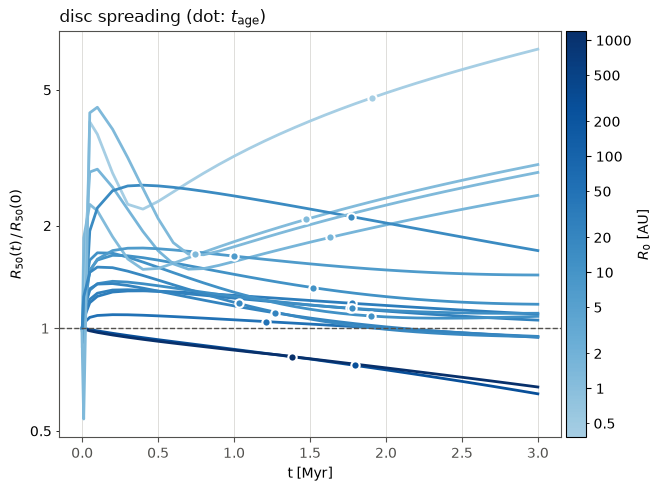

In [6]:
# =====================================================================================
# 2b. Figure: R50 growth
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"    # text / reference lines / grid
cmap = mcolors.LinearSegmentedColormap.from_list("blues", plt.cm.Blues(np.linspace(0.35, 1.0, 256)))  # one hue, light->dark
norm = mcolors.LogNorm(vmin=comparisons.R0_au.min(), vmax=comparisons.R0_au.max())

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)   # single Axes, not an array
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_color(MUTED)
ax.tick_params(colors=MUTED)

plain = FuncFormatter(lambda v, _: f"{v:g}")         # plain tick numbers on log axes
def tidy_log(ax, which="xy"):
    """Plain tick labels on log axes (call AFTER limits are set): decades always labelled;
    minor ticks at 2 and 5, labelled only when the axis spans < 2 decades."""
    for a, lims in ([(ax.xaxis, ax.get_xlim())] if "x" in which else []) + ([(ax.yaxis, ax.get_ylim())] if "y" in which else []):
        a.set_major_formatter(plain)
        a.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
        a.set_minor_formatter(plain if np.log10(lims[1] / lims[0]) < 2 else NullFormatter())

# R50(t) / R50(0)
for disc_id, (ts, r50s) in r50_tracks.items():
    ts, r50s = np.asarray(ts), np.asarray(r50s)
    c = cmap(norm(draws.loc[disc_id, "R0_au"]))
    ax.plot(ts, r50s / r50s[0], color=c, lw=2)
    row = comparisons.loc[comparisons.id == disc_id].iloc[0]
    if np.isfinite(row.get("R50_growth", np.nan)):
        ax.plot(row.t_age_Myr, row.R50_growth, "o", ms=6, color=c, mec="white", mew=1.5, zorder=3)

ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_yscale("log"); tidy_log(ax, "y")
ax.set_xlabel("t [Myr]"); ax.set_ylabel(r"$R_{50}(t)\,/\,R_{50}(0)$")
ax.set_title(r"disc spreading (dot: $t_{\rm age}$)", loc="left", color=INK)

cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$R_0$ [AU]", pad=0.01)
cb.ax.yaxis.set_major_formatter(plain)
cb.ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
cb.ax.yaxis.set_minor_formatter(plain)
plt.show()

## Next sections (to be added)
- **Fig. 4 reproduction:** $\dot M$ vs $M$ at each disc's sampled age, against Malanga's analytic model ($\omega = 0$ and $0.4$, same draws) and the Lupus sources near $1\,M_\odot$. Flags to carry through: GI-flagged discs and discs beyond the grid.
